<a href="https://colab.research.google.com/github/dancingdinosaur/NexoSci-project/blob/main/Student_stuff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
uploaded = files.upload()
import pandas as pd
# header=0 ensures the title row isn't treated as data!
df = pd.read_csv("training_data.csv", header=0)
df.head()

Saving training_data.csv to training_data (1).csv


,student,study_hours,training_hours,sleep_hours,academic_score,sports_score,injury
0,Student_1,13,12,7.0,81.9,75.8,No
1,Student_2,8,6,7.0,72.0,63.0,No
2,Student_3,12,6,NaN,77.6,75.3,No
3,Student_4,20,18,7.0,89.3,98.9,Yes
4,Student_5,21,19,9.0,100.0,95.7,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student         27 non-null     object 
 1   study_hours     27 non-null     int64  
 2   training_hours  27 non-null     int64  
 3   sleep_hours     25 non-null     float64
 4   academic_score  26 non-null     float64
 5   sports_score    27 non-null     float64
 6   injury          27 non-null     object 
dtypes: float64(3), int64(2), object(2)
memory usage: 1.6+ KB


In [20]:
df.describe()

,study_hours,training_hours,sleep_hours,academic_score,sports_score
count,27.000000,27.000000,25.000000,26.000000,27.000000
mean,14.888889,11.703704,9.920000,82.703846,79.218519
std,8.409396,5.875731,14.645591,12.595538,10.337387
min,6.000000,-5.000000,5.000000,57.700000,61.500000
25%,8.000000,7.000000,6.000000,72.325000,72.600000
50%,14.000000,12.000000,7.000000,82.750000,78.900000
75%,20.000000,16.500000,8.000000,93.150000,86.800000
max,45.000000,19.000000,80.000000,100.000000,98.900000


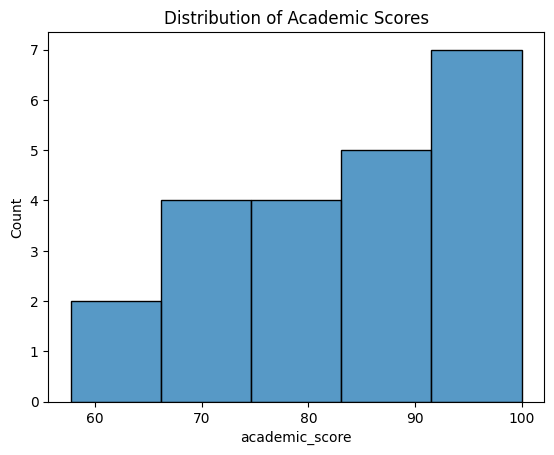

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(data=df_clean, x="academic_score", bins=5)
plt.title("Distribution of Academic Scores")
plt.show()

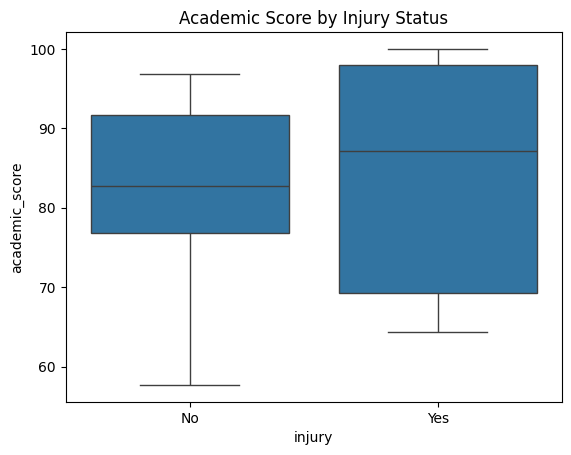

In [22]:
sns.boxplot(data=df_clean, x="injury", y="academic_score")
plt.title("Academic Score by Injury Status")
plt.show()

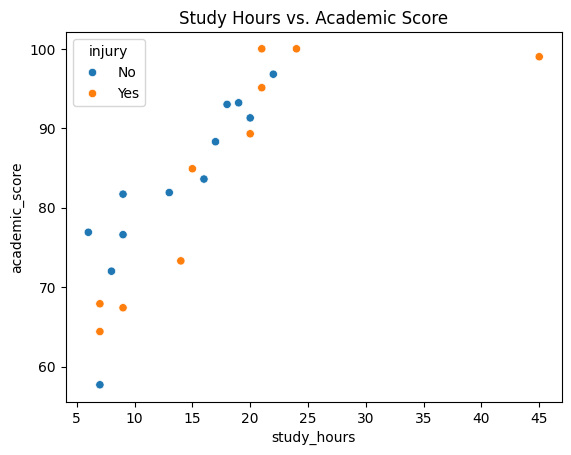

In [23]:
sns.scatterplot(data=df_clean, x="study_hours",
y="academic_score", hue="injury")
plt.title("Study Hours vs. Academic Score")
plt.show()


                study_hours  training_hours  sleep_hours  academic_score  \
study_hours            1.00            0.35        -0.05            0.79   
training_hours         0.35            1.00        -0.08            0.23   
sleep_hours           -0.05           -0.08         1.00            0.34   
academic_score         0.79            0.23         0.34            1.00   
sports_score           0.30            0.92         0.04            0.26   

                sports_score  
study_hours             0.30  
training_hours          0.92  
sleep_hours             0.04  
academic_score          0.26  
sports_score            1.00  


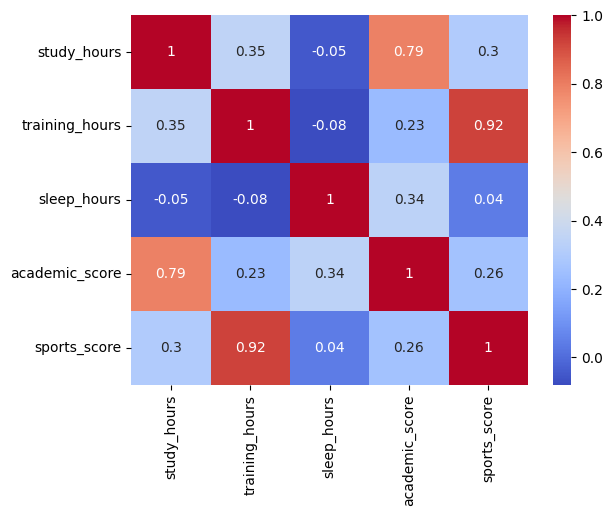

In [24]:
corr_matrix = df_clean.corr(numeric_only=True).round(2)
print(corr_matrix)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

In [25]:
import statsmodels.api as sm
X = sm.add_constant(df_clean["study_hours"])
Y = df_clean["academic_score"]
model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:         academic_score   R-squared:                       0.624
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     33.24
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.22e-05
Time:                        22:41:41   Log-Likelihood:                -75.451
No. Observations:                  22   AIC:                             154.9
Df Residuals:                      20   BIC:                             157.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          65.5932      3.508     18.699      

In [26]:
X = df_clean[["study_hours", "sleep_hours"]]
X = sm.add_constant(X)
Y = df_clean["academic_score"]
model_mult = sm.OLS(Y, X).fit()
print(model_mult.summary())


                            OLS Regression Results                            
Dep. Variable:         academic_score   R-squared:                       0.766
Model:                            OLS   Adj. R-squared:                  0.741
Method:                 Least Squares   F-statistic:                     31.08
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.02e-06
Time:                        22:48:02   Log-Likelihood:                -70.247
No. Observations:                  22   AIC:                             146.5
Df Residuals:                      19   BIC:                             149.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          38.5400      8.471      4.550      

In [28]:
# Convert "Yes/No" text into 1 and 0 math codes
df_clean['injury_code'] = df_clean['injury'].map(
{'Yes': 1, 'No': 0})

In [29]:
X = sm.add_constant(df_clean["sleep_hours"])
Y = df_clean["injury_code"]
model_log = sm.Logit(Y, X).fit()
print(model_log.summary())

Optimization terminated successfully.
         Current function value: 0.641475
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:            injury_code   No. Observations:                   22
Model:                          Logit   Df Residuals:                       20
Method:                           MLE   Df Model:                            1
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                 0.06899
Time:                        23:14:23   Log-Likelihood:                -14.112
converged:                       True   LL-Null:                       -15.158
Covariance Type:            nonrobust   LLR p-value:                    0.1481
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.6010      2.791      1.290      0.197      -1.869       9.071
sleep_hours    -0.5431    

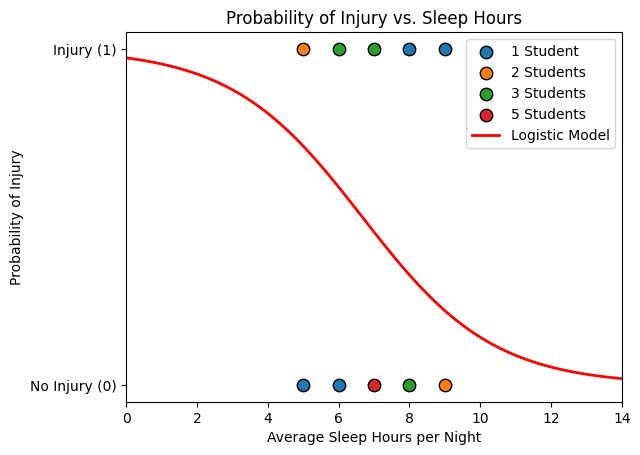

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Group the data to count how many students share the exact same coordinates
point_counts = df_clean.groupby(['sleep_hours', 'injury_code']).size().reset_index(name='count')

# 2. Define a list of distinct colors for the different counts
# (e.g., Blue for 1, Orange for 2, Green for 3+)
color_palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# 3. Loop through the unique counts and plot them with different colors
unique_counts = sorted(point_counts['count'].unique())

for i, count_val in enumerate(unique_counts):
    # Filter for points that have this specific count
    subset = point_counts[point_counts['count'] == count_val]

    # Define plural/singular for the legend (e.g., "1 Student" vs "2 Students")
    label_text = f"{count_val} Student{'s' if count_val > 1 else ''}"

    # Plot this specific group
    plt.scatter(subset["sleep_hours"], subset["injury_code"],
                color=color_palette[i % len(color_palette)],
                label=label_text,
                s=80, edgecolors="black", zorder=5)

# 4. Create the X-axis for the theoretical line (from 0 to 14 hours, 100 smooth points)
x_line = np.linspace(0, 14, 100)

# 5. Calculate the Y-values (Probability) using our Logistic Equation
# (z = 3.60 - 0.54 * Sleep Hours)
z = 3.60 - 0.54 * x_line
y_prob = 1 / (1 + np.exp(-z))

# 6. Plot the S-Curve Line
plt.plot(x_line, y_prob, color="red", linewidth=2, label="Logistic Model", zorder=1)

# 7. Format the Graph
plt.title("Probability of Injury vs. Sleep Hours")
plt.xlabel("Average Sleep Hours per Night")
plt.ylabel("Probability of Injury")
plt.yticks([0, 1], ["No Injury (0)", "Injury (1)"])
plt.xlim(0, 14)

# Place the legend in a clear spot
plt.legend()

plt.show()

In [19]:
# 1. Drop rows with Missing Values (NaN)
df_clean = df.dropna()
# 2. Filter out impossible Outliers
# Keep only rows with sleep_hours <= 24 AND training_hours
df_clean = df_clean[(df_clean['sleep_hours'] <= 24) &
(df_clean['training_hours'] >= 0)]